## Embeddings


Embeddings são representações numéricas que traduzem dados de alta dimensão, como texto, imagens ou áudio, em vetores de dimensão reduzida. Esses vetores preservam relações semânticas ou contextuais do dado original, permitindo que informações complexas sejam manipuladas de forma mais eficiente em cálculos e algoritmos.

No caso de textos, por exemplo, um embedding transforma palavras, frases ou documentos em números de tal forma que palavras com significados semelhantes fiquem próximas no espaço vetorial. Por exemplo, podemos dizer que a palavra homem está para a palavra rei, da mesma forma que a palavra mulher está para a palavra rainha. Esses significados semânticos servem como ferramenta para que possamos obter contextos dentro de situações em que precisamos dele.


In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader

from dotenv import load_dotenv
import os

from tqdm import tqdm

load_dotenv()

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")

In [101]:
embedding_size = 1536
embedding_model = "text-embedding-3-small"
embeddings = OpenAIEmbeddings(model=embedding_model, dimensions=embedding_size)

## Carregando os dados:

Instanciando o [`PyPDFLoader`](https://python.langchain.com/docs/integrations/document_loaders/pypdfloader/), temos um objeto de loader do lanchain. No momento em que essa classe é instanciada, colocamos o caminho do arquivo PDF que queremos ler, e o objeto resultante tem um método chamado .load(). 
Esse método permite a leitura do arquivo PDF, e o resultado é o texto presente no PDF dentro de um objeto "Document", que faz parte da biblioteca do langchain e é a base dessa dinâmica de leitura de documentos da biblioteca.

In [102]:
file_path_ed_financeira = "../data/educacao_financeira.pdf"
file_path_historia = "../data/historia.pdf"
loader_historia = PyPDFLoader(file_path_historia)
loader_ed_financeira = PyPDFLoader(file_path_ed_financeira)
pages_historia = loader_historia.load()
pages_ed_financeira = loader_ed_financeira.load()

In [103]:
# Concatenante todo o conteudo em uma string só

all_content_pages_historia = "\n\n".join([page.page_content for page in pages_historia])
all_content_pages_ed_financeira = "\n\n".join([page.page_content for page in pages_ed_financeira])

## Text Splitter

Utilizamos uma técnica de text splitting para quebrar os textos em chunks (fragmentos menores). Isso é interessante no nosso contexto porque facilita o processamento e a análise de textos longos em tarefas como classificação ou geração de respostas. 

[`Recursive Text Splitter`](https://python.langchain.com/docs/how_to/recursive_text_splitter/).

In [158]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1200,
    chunk_overlap=600,
    length_function=len,
    is_separator_regex=False,
)

In [159]:
##Aqui, temos como output uma lista de documents, onde cada document é um chunk do documento original
chunks_historia = text_splitter.split_documents(pages_historia)
chunks_ed_financeira = text_splitter.split_documents(pages_ed_financeira)

In [160]:
len(chunks_historia), len(chunks_ed_financeira)

(539, 396)

## Injetando a conversação

In [161]:
import json

with open("../data/conversation/conversation_data_major_2.json", "r", encoding="utf-8") as f:
    loaded_content = json.load(f)   

In [162]:
loaded_content[:5]

[{'summary': 'Persona 1 introduziu o tópico da Idade Média, destacando-o como um período fascinante da história e questionando o que o torna tão intrigante para muitas pessoas.',
  'persona': 'Persona 1',
  'message': 'Olá! Hoje pensei que poderíamos começar nossa conversa falando sobre um dos períodos mais fascinantes da história: a Idade Média. O que você acha que torna essa época tão intrigante para tantas pessoas?'},
 {'summary': 'A conversa gira em torno da Idade Média, com Persona 1 sugerindo discutir esse período histórico fascinante. Persona 2 concorda, destacando que a Idade Média atrai muitas pessoas devido ao seu mistério e transformação, além das histórias de cavaleiros e castelos que estimulam a imaginação.',
  'persona': 'Persona 2',
  'message': 'Olá! A Idade Média é realmente fascinante. Acho que o que atrai muitas pessoas é a combinação de mistério e transformação. Foi uma época de grandes mudanças, com o surgimento de novas ideias, culturas e, claro, as histórias de c

In [163]:
chunks_conversation = []
for item in loaded_content:
    chunks_conversation.append(item['summary'])
    # chunks_conversation.append(item['message'])


In [164]:
len(chunks_conversation)

28

## Criando embeddings

Aqui, nós criamos os embeddings utilizando o [`OpenAIEmbeddings`](https://python.langchain.com/docs/integrations/text_embedding/openai/), e transformamos esses embeddings em arrays do numpy, que otimiza o uso desses embeddings para cálculos.

Criamos embeddings para os textos de história e educação financeira separadamente, e depois concatenamos (juntamos) os dois tipos de embeddings em um array só com todos os embeddings

In [165]:
vectors_conversation = np.array(embeddings.embed_documents([chunk for chunk in chunks_conversation]))

In [166]:
vectors_historia = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_historia]))

In [167]:
vectors_ed_financeira = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_ed_financeira]))

In [168]:
all_vectors = np.concatenate([vectors_conversation, vectors_historia, vectors_ed_financeira], axis=0)

In [169]:
vectors_conversation.shape, vectors_ed_financeira.shape, vectors_historia.shape, all_vectors.shape

((28, 1536), (396, 1536), (539, 1536), (963, 1536))

## Reduzindo a dimensionalidade

Embeddings possuem uma quantidade significativa de dimensões. Para facilitar a compreensão, pense nas três dimensões que observamos no espaço ao nosso redor: altura, largura e profundidade. Com elas, conseguimos descrever a posição de qualquer objeto no espaço. Agora, imagine lidar com mais de 1000 dimensões. É impossível visualizar ou compreender intuitivamente esse espaço, mesmo que ele carregue significados importantes.

Para lidar com essa complexidade, utilizamos técnicas de redução de dimensionalidade, que permitem diminuir o número de dimensões sem perder as características principais dos dados. Uma dessas técnicas amplamente utilizadas é o t-SNE (t-Distributed Stochastic Neighbor Embedding). Essa técnica é capaz de projetar dados de alta dimensão em um espaço de dimensões menores, geralmente 2 ou 3, preservando as relações de proximidade entre os pontos no espaço original.

Não é necessário nos preocuparmos com os detalhes matemáticos dessa técnica, pois bibliotecas como o sklearn.manifold já oferecem implementações eficientes. Podemos utilizá-la para reduzir os nossos embeddings para 2 dimensões, permitindo que eles sejam visualizados em um plano 2D.

In [199]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=135)
all_vectors_tsne = tsne.fit_transform(all_vectors)

In [200]:
len(vectors_conversation), len(vectors_historia), len(vectors_ed_financeira), len(all_vectors_tsne)

(28, 539, 396, 963)

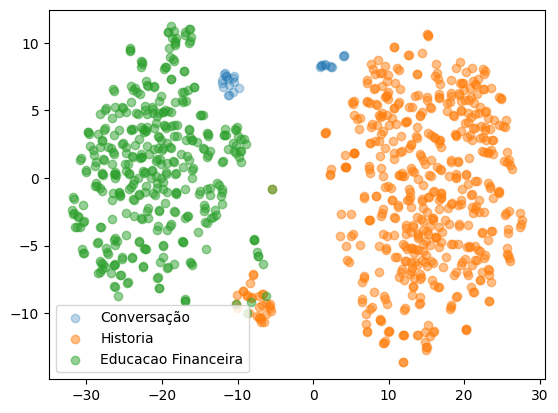

In [201]:
plt.scatter(all_vectors_tsne[:len(vectors_conversation), 0], all_vectors_tsne[:len(vectors_conversation), 1], label="Conversação", alpha=0.3)

plt.scatter(all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 0], all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 1], label="Historia", alpha=0.5)
plt.scatter(all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 0], all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 1], label="Educacao Financeira", alpha=0.5)
plt.legend()
plt.show()

In [202]:
centroid_historia = np.mean(vectors_historia, axis=0)
centroid_ed_financeira = np.mean(vectors_ed_financeira, axis=0)

In [203]:
# import cos similarity from sklearn
from sklearn.metrics.pairwise import cosine_similarity

# Compare all summary vectors to centroids
similarity_to_historia = cosine_similarity(vectors_conversation, centroid_historia.reshape(1, -1))
similarity_to_ed_financeira = cosine_similarity(vectors_conversation, centroid_ed_financeira.reshape(1, -1))

In [204]:
content_and_similarities = []
for i in range(len(chunks_conversation)):
    content_and_similarities.append({
        "chunk": chunks_conversation[i],
        "similarity_to_historia": similarity_to_historia[i, 0],
        "similarity_to_ed_financeira": similarity_to_ed_financeira[i, 0]
    })

In [205]:
df = pd.DataFrame(content_and_similarities)

In [206]:
df.sort_values(by="similarity_to_ed_financeira", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_ed_financeira
17,A conversa entre as duas personas foca na evol...,0.392736,0.616204
21,A conversa entre as duas personas foca na impo...,0.350441,0.612334
19,A conversa entre as duas personas foca na impo...,0.378248,0.597564
15,A conversa entre as duas personas foca na impo...,0.379113,0.595317
18,A conversa entre as duas personas foca na impo...,0.390385,0.586191
14,A conversa entre as duas personas gira em torn...,0.427393,0.583248
22,A conversa entre as duas personas foca na impo...,0.359187,0.578946
20,A conversa entre as duas personas foca na impo...,0.350600,0.578837
25,A conversa entre as duas personas foca na impo...,0.363706,0.577723
27,A conversa entre as duas personas focou princi...,0.334889,0.567501


In [207]:
df.sort_values(by="similarity_to_historia", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_ed_financeira
3,A conversa entre as duas personas gira em torn...,0.516400,0.316552
4,A conversa entre as duas personas gira em torn...,0.513093,0.364638
5,A conversa entre as duas personas gira em torn...,0.505165,0.391991
1,"A conversa gira em torno da Idade Média, com P...",0.500064,0.341224
9,A conversa entre as duas personas começou com ...,0.493399,0.522696
6,A conversa entre as duas personas começou com ...,0.482815,0.426094
7,A conversa entre as duas personas começou com ...,0.481685,0.419078
11,A conversa entre as duas personas começou disc...,0.473017,0.510609
10,A conversa entre as duas personas começou com ...,0.471760,0.499796
0,"Persona 1 introduziu o tópico da Idade Média, ...",0.471346,0.297177


In [208]:
example_ed_fin = df.sort_values(by="similarity_to_ed_financeira", ascending=False).head(10)['chunk'].values
for x in example_ed_fin:
    print(x)
    print("-----")

A conversa entre as duas personas foca na evolução das práticas financeiras pessoais e a importância crescente da educação financeira. Persona 2 destaca que, enquanto no passado as finanças eram mais simples, hoje em dia há uma variedade de produtos financeiros que exigem maior conhecimento. Ambos concordam que a educação financeira é crucial e deveria ser integrada ao currículo escolar para preparar os jovens para decisões financeiras informadas, evitando dívidas e ensinando habilidades de orçamento e planejamento. Além disso, discutem a importância do planejamento para a aposentadoria desde cedo e o papel dos investimentos como parte de uma estratégia financeira eficaz.
-----
A conversa entre as duas personas foca na importância da educação financeira, especialmente sua integração no currículo escolar, para preparar os jovens a tomarem decisões financeiras informadas. Elas discutem como isso pode ajudar a evitar dívidas e ensinar habilidades de vida, como orçamento e planejamento de 

In [209]:
example_ed_hist = df.sort_values(by="similarity_to_historia", ascending=False).head(10)['chunk'].values
for x in example_ed_hist:
    print(x)
    print("-----")

A conversa entre as duas personas gira em torno da Idade Média, destacando seu fascínio devido ao mistério e transformação desse período. Elas discutem o impacto das Cruzadas na Europa medieval, enfatizando como esses eventos influenciaram a política, religião e abriram rotas comerciais e culturais entre o Oriente e o Ocidente, contribuindo para a troca de ideias e tecnologias que moldaram a Europa moderna.
-----
A conversa entre as duas personas gira em torno da Idade Média, destacando seu fascínio devido ao mistério e transformação, com foco nas Cruzadas e seu impacto na Europa medieval. As Cruzadas não apenas influenciaram a política e a religião, mas também abriram rotas comerciais e culturais, promovendo a troca de ideias e tecnologias. A discussão evolui para considerar paralelos entre o desenvolvimento econômico da Idade Média e o mundo atual, sugerindo uma conexão entre as trocas culturais e comerciais daquele período e o crescimento econômico contemporâneo.
-----
A conversa en

## Análise de similaridade 

In [210]:
vectors_conversation

array([[-0.01503765, -0.00565144, -0.01711861, ...,  0.00205084,
         0.01827957, -0.00729978],
       [-0.00707935,  0.01096884,  0.00444979, ..., -0.00939763,
         0.0148109 ,  0.01858181],
       [-0.02243043, -0.00020956,  0.01158905, ..., -0.0112269 ,
         0.02186967,  0.00937522],
       ...,
       [ 0.0193781 ,  0.00252241,  0.02708928, ..., -0.01376996,
         0.01798858,  0.03610234],
       [ 0.01012995, -0.01479912,  0.00538699, ..., -0.01720079,
         0.02313118,  0.03308671],
       [ 0.03513793, -0.01637458,  0.00795612, ..., -0.00642462,
         0.00345793,  0.0321584 ]], shape=(28, 1536))

In [216]:
sims_delta_s = []
cosine_similarities = []
for i in range(1, len(vectors_conversation)):
    delta = vectors_conversation[i] - vectors_conversation[i-1]
    delta_cos_sim = cosine_similarity(vectors_conversation[i].reshape(1, -1), vectors_conversation[i-1].reshape(1, -1))[0,0]
    sims_delta_s.append(delta)
    cosine_similarities.append(delta_cos_sim)
sims_delta_s = np.array(sims_delta_s)
cosine_similarities = np.array(cosine_similarities)

In [218]:
sims_delta_s.shape, cosine_similarities.shape

((27, 1536), (27,))

In [213]:
# p2, p1, p2 ...
mods = np.linalg.norm(sims_delta_s, axis=1)

In [220]:
idxs_persona_1 = list(range(1, len(mods), 2))
idxs_persona_2 = list(range(0, len(mods), 2))

mods_persona_1 = mods[idxs_persona_1]
mods_persona_2 = mods[idxs_persona_2]

mods_cos_similarities_persona_1 = cosine_similarities[idxs_persona_1]
mods_cos_similarities_persona_2 = cosine_similarities[idxs_persona_2]

In [221]:
mods_persona_1.mean(), mods_persona_2.mean()

(np.float64(0.4701138123618889), np.float64(0.4507355632424364))

In [222]:
mods_cos_similarities_persona_1.mean(), mods_cos_similarities_persona_2.mean()

(np.float64(0.878521654749471), np.float64(0.8827675017904834))

In [233]:
mods_cos_similarities_persona_1.std(), mods_cos_similarities_persona_2.std()

(np.float64(0.07611794174757969), np.float64(0.08759838862421479))